# Reproduce one case from scratch: is Lincolnshire really warming?

This notebook redoes the Trend Detective's headline case **without our server code**: it downloads the
numbers straight from the NASA POWER API, averages the grid cells, removes the seasons and runs the same tests.
If you get the same answer as the app, you don't have to trust us.

*AI-use note: drafted with Claude (Anthropic) during the hackathon; every number below is computed by the code.*

**To run it:** `pip install requests numpy pandas pymannkendall scipy matplotlib`, then run all cells (about 30 s; it downloads from NASA POWER). The saved outputs below are from a clean run on Sun 15 Nov 2026.

In [1]:
import io, requests, numpy as np, pandas as pd, pymannkendall as mk
from scipy import stats

BOX = dict(lat_min=52.6, lat_max=53.7, lon_min=-1.0, lon_max=0.4)   # Lincolnshire
# POWER's regional API needs at least 2 degrees each way, so ask for a slightly wider area...
q = {"parameters": "T2M", "community": "AG", "latitude-min": 52.15, "latitude-max": 54.15,
     "longitude-min": -1.3, "longitude-max": 0.7, "start": 1981, "end": 2025, "format": "JSON"}
r = requests.get("https://power.larc.nasa.gov/api/temporal/monthly/regional", params=q, timeout=300)
r.raise_for_status()
features = r.json()["features"]
print(len(features), "grid cells returned")

16 grid cells returned


## 1. Keep only the cells inside the box, and average them (weighted by cos latitude)

In [2]:
cols, w = {}, []
for f in features:
    lon, lat = f["geometry"]["coordinates"][:2]
    if BOX["lat_min"] <= lat <= BOX["lat_max"] and BOX["lon_min"] <= lon <= BOX["lon_max"]:
        raw = f["properties"]["parameter"]["T2M"]
        s = pd.Series({pd.Timestamp(int(k[:4]), int(k[4:]), 1): v for k, v in raw.items() if k[4:] != "13"})
        cols[(lat, lon)] = s.where(s > -900)
        w.append(np.cos(np.radians(lat)))
df = pd.DataFrame(cols).sort_index()
series = (df * w).sum(axis=1) / (df.notna() * w).sum(axis=1)
print(len(cols), "cells inside the box;", series.index[0].date(), "to", series.index[-1].date())
series.tail()

4 cells inside the box; 1981-01-01 to 2025-12-01


2025-08-01    17.283479
2025-09-01    14.302573
2025-10-01    11.064591
2025-11-01     7.904883
2025-12-01     6.594357
dtype: float64

## 2. Remove the seasons (each month minus that calendar month's average)

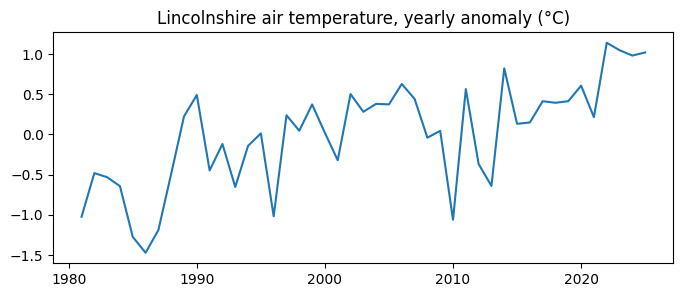

In [3]:
anom = series - series.groupby(series.index.month).transform("mean")
anom.groupby(anom.index.year).mean().plot(title="Lincolnshire air temperature, yearly anomaly (°C)", figsize=(8, 3));

## 3. The tests
* **Typical analysis**: a straight line through the months, treating each month as independent.
* **Our test**: Mann–Kendall with the Hamed & Rao (1998) correction for persistence (lag 12), and Sen's slope.

In [4]:
t = (anom.index.year + (anom.index.month - 0.5) / 12).to_numpy()
ols = stats.linregress(t, anom.to_numpy())
hr = mk.hamed_rao_modification_test(anom.to_numpy(), lag=12)
print(f"Typical straight line : {ols.slope * 10:+.3f} °C/decade, p = {ols.pvalue:.2g}")
print(f"Hamed–Rao Mann–Kendall : p = {hr.p:.2g}")
print(f"Sen's slope            : {hr.slope * 120:+.3f} °C/decade")

Typical straight line : +0.345 °C/decade, p = 2e-18
Hamed–Rao Mann–Kendall : p = 4.7e-10
Sen's slope            : +0.333 °C/decade


## 4. Compare with the app (the live site, or a local copy)

In [5]:
APIS = ["https://kaakserver.tail042e87.ts.net/trend-detective/api", "http://127.0.0.1:8000/api"]  # live site, then a local copy
for base in APIS:
    try:
        app = requests.get(base + "/analyse", params={"var": "T2M", **BOX}, timeout=60).json()["result"]
        print("App (" + base + ") says:", app["verdict"]["headline"])
        print(f"App Sen slope {app['sen_slope_per_decade']:+.3f} vs notebook {hr.slope * 120:+.3f} °C/decade")
        break
    except Exception as e:
        print("Couldn't reach", base, type(e).__name__)
else:
    print("App not reachable; the README lists its answer (+0.33 °C/decade, strong evidence).")

App (https://kaakserver.tail042e87.ts.net/trend-detective/api) says: Strong evidence it is rising: about 0.333 °C per decade.
App Sen slope +0.333 vs notebook +0.333 °C/decade


## 5. Check it somewhere else
* The same MERRA-2 field in **NASA Giovanni** (area-averaged time series, free Earthdata login):
  https://giovanni.gsfc.nasa.gov/giovanni/#service=ArAvTs&starttime=1981-01-01T00:00:00Z&endtime=2025-12-31T23:59:59Z&bbox=-1.0,52.6,0.4,53.7&data=M2TMNXSLV_5_12_4_T2M
* An independent record: the Met Office **Central England Temperature** (HadCET), which the app also shows as a second witness.